# TimesFM-2.5 als vierter Experte + Prüfung von Chronos-2

Dieses Notebook baut auf `volatilitaet_chronos2_har_garch.ipynb` auf und verwendet exakt dasselbe Setup (gleiche Ursprünge, Horizonte, 21 Quantile, log-RV als Input, Kontext 1024).

1. **Chronos-Check:** Welche Chronos-Variante (`chronos-2-small` oder `chronos-2`) hat die gespeicherten Prognosen in `results/` erzeugt? Auf CPU wählt Notebook 1 automatisch die kleine Variante. Ein Vergleich mit dem grossen TimesFM wäre dann unfair.
2. **TimesFM-2.5** zero-shot für alle Coins → `results/<COIN>__TimesFM-2.5.parquet`
3. **Chronos-2 voll** (nur falls nötig) → `results/<COIN>__Chronos-2-full.parquet`
4. **Auswertung:** Metriken, Oracle-Analyse, Fehlerkorrelation, Diebold-Mariano. Lohnt sich TimesFM für das Gate?

**Bestehende Dateien werden nicht überschrieben.** Neue Experten erscheinen in `01_kombination.ipynb`, sobald sie in `POOL` stehen.

**Laufzeit:** ca. 20–40 Minuten auf CPU. Beim ersten Lauf werden die Modelle von Hugging Face geladen (ca. 1–1.5 GB).

In [7]:
import json, time
from pathlib import Path
from statistics import NormalDist

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from tqdm.auto import tqdm

DATA_DIR, RESULTS_DIR = Path("data"), Path("results")

# ---- Setup wie in Notebook 1 ----
SYMBOLS = ["BTCUSDT", "ETHUSDT", "SOLUSDT"]
HORIZONS = [1, 5]
QUANTILES = [0.01, 0.05, 0.1, 0.15, 0.2, 0.25, 0.3, 0.35, 0.4, 0.45, 0.5,
             0.55, 0.6, 0.65, 0.7, 0.75, 0.8, 0.85, 0.9, 0.95, 0.99]
QCOLS = [f"q{q:.2f}" for q in QUANTILES]
MIN_HISTORY = 500
CONTEXT = 1024                      # wie CHRONOS_CONTEXT in Notebook 1
OLD_TRAIN_END, OLD_VAL_END = "2023-12-31", "2024-12-31"   # Split-Spalte wie Notebook 1 (01_kombination überschreibt sie)

# ---- Modelle ----
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
TIMESFM_REPO = "google/timesfm-2.5-200m-pytorch"
TIMESFM_BATCH = 128                 # per_core_batch_size: Default 1 wäre ca. 8x langsamer
CHRONOS_FULL, CHRONOS_SMALL = "amazon/chronos-2", "autogluon/chronos-2-small"
CHRONOS_BATCH = 128
N_CHECK = 60                        # Ursprünge für den Chronos-Check

# ---- Auswertung (Splits wie 01_kombination.ipynb) ----
TRAIN_END, VAL_END = "2025-10-31", "2026-02-28"
BASELINE = "RW"

_LV = np.asarray(QUANTILES)
_QMASS = (np.r_[_LV[1:], 1.0] - np.r_[0.0, _LV[:-1]]) / 2     # Wahrscheinlichkeitsmasse je Quantil (Trapez)
_QMASS = _QMASS / _QMASS.sum()

print("Device:", DEVICE, "| torch threads:", torch.get_num_threads())

Device: cpu | torch threads: 10


## 1. Daten und Ursprünge

Gleiche Logik wie in Notebook 1: Ein Ursprung $t$ ist der letzte bekannte Tag, der erste Ursprung liegt nach 500 Tagen Historie. Die Anzahl Ursprünge muss mit den gespeicherten Dateien übereinstimmen.

In [8]:
class RVSeries:
    def __init__(self, sid, df):
        self.sid = sid
        self.dates = df.index
        self.rv = df["rv"].to_numpy(float)
        self.ret = df["ret"].to_numpy(float)
        self.logrv = np.log(self.rv)
        self.origins = np.arange(MIN_HISTORY - 1, len(df) - max(HORIZONS))


def assign_old_split(target_dates):
    td = pd.to_datetime(target_dates)
    return np.where(td <= pd.Timestamp(OLD_TRAIN_END), "train",
                    np.where(td <= pd.Timestamp(OLD_VAL_END), "val", "test"))


def contexts_for(s, origins):
    L = s.logrv.astype(np.float32)
    return [L[max(0, t - CONTEXT + 1): t + 1] for t in origins]


def mean_from_quantiles(q):
    # wie in Notebook 1: E[Y] als Integral der Quantilfunktion
    return q @ _QMASS


series = {sym: RVSeries(sym, pd.read_parquet(DATA_DIR / f"{sym}_daily.parquet")) for sym in SYMBOLS}
for s in series.values():
    n_stored = (pd.read_parquet(RESULTS_DIR / f"{s.sid}__HAR.parquet")["h"] == 1).sum()
    print(f"{s.sid}: {len(s.origins)} Ursprünge (gespeichert: {n_stored})")

BTCUSDT: 1922 Ursprünge (gespeichert: 1922)
ETHUSDT: 1922 Ursprünge (gespeichert: 1922)
SOLUSDT: 1702 Ursprünge (gespeichert: 1702)


## 2. TimesFM-Quantile: 9 → 21

TimesFM-2.5 liefert nur die Quantile 0.1, 0.2, …, 0.9. Alle anderen Experten haben 21 Quantile (0.01 … 0.99). Damit TimesFM ohne Änderung in die Pipeline passt, wird ergänzt, und zwar **in Logs** auf der Normal-Skala $z = \Phi^{-1}(\tau)$:

- **Innen** (0.15, 0.25, …, 0.85): lineare Interpolation zwischen den Nachbarn. Die nativen Werte bleiben exakt erhalten.
- **Ränder** (0.01, 0.05, 0.95, 0.99): Extrapolation mit der lokalen Steigung am jeweiligen Rand (aus $q_{0.1}..q_{0.3}$ bzw. $q_{0.7}..q_{0.9}$). Das entspricht einem normalverteilten Rand der log-RV und erlaubt asymmetrische Ränder.

Ist die log-RV normalverteilt, ist die Ergänzung exakt. Das ist eine **Annahme**. Deshalb gibt es in der Auswertung einen Robustheitscheck, der nur die nativen Quantile 0.1 … 0.9 verwendet (Pinball9, Cov80).

Der Mittelwert wird wie bei Chronos aus den Quantilen integriert. Den Punktwert von TimesFM selbst verwenden wir **nicht**: Er ist eine Prognose in Logs, und `exp` davon liegt beim Median der RV, nicht beim Erwartungswert. TimesFM wäre damit systematisch zu tief.

In [9]:
_ND = NormalDist()
NATIVE = np.array([0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9])
Z_NATIVE = np.array([_ND.inv_cdf(p) for p in NATIVE])
Z_TARGET = np.array([_ND.inv_cdf(p) for p in QUANTILES])


def expand_quantiles(logq9):
    # (..., 9) Log-Quantile auf 0.1..0.9 -> (..., 21) Log-Quantile auf QUANTILES
    q = np.asarray(logq9, float)
    out = np.empty(q.shape[:-1] + (len(QUANTILES),))
    lo_slope = np.maximum((q[..., 2] - q[..., 0]) / (Z_NATIVE[2] - Z_NATIVE[0]), 1e-6)
    hi_slope = np.maximum((q[..., 8] - q[..., 6]) / (Z_NATIVE[8] - Z_NATIVE[6]), 1e-6)
    for k, z in enumerate(Z_TARGET):
        if z < Z_NATIVE[0] - 1e-12:
            out[..., k] = q[..., 0] + lo_slope * (z - Z_NATIVE[0])
        elif z > Z_NATIVE[-1] + 1e-12:
            out[..., k] = q[..., 8] + hi_slope * (z - Z_NATIVE[-1])
        else:
            j = int(np.clip(np.searchsorted(Z_NATIVE, z), 1, 8))
            w = (z - Z_NATIVE[j - 1]) / (Z_NATIVE[j] - Z_NATIVE[j - 1])
            out[..., k] = (1 - w) * q[..., j - 1] + w * q[..., j]
    return out


# Kontrolle: bei normalverteilter log-RV muss die Ergänzung exakt sein
nd = NormalDist(-7.0, 0.6)
exact = np.array([nd.inv_cdf(p) for p in QUANTILES])
approx = expand_quantiles(np.array([nd.inv_cdf(p) for p in NATIVE]))
print("max. Fehler bei Normalverteilung:", float(np.abs(approx - exact).max()))

max. Fehler bei Normalverteilung: 8.881784197001252e-16


## 3. Experten

Beide Klassen haben dieselbe Schnittstelle wie in Notebook 1 (`name`, `forecast(s, origins)` → `mean`, `q`).

**TimesFM-2.5:** gleiches Setup wie Chronos (log-RV, Kontext 1024, Horizont 5 → Schritte 1 und 5). Einstellungen beim `compile`:
- `per_core_batch_size=128`: Der Default 1 macht es etwa 8× langsamer (Resource Check).
- `use_continuous_quantile_head=True`, `fix_quantile_crossing=True`: Quantile statt nur Punktwert, monoton.
- `infer_is_positive=False`: Die log-RV ist negativ, es gibt keine Positivitäts-Annahme.

**Chronos-2:** identisch zu Notebook 1, aber das Modell ist frei wählbar.

`run_expert` arbeitet wie in Notebook 1, überschreibt aber nie eine bestehende Datei und schreibt die Laufzeiten in `results/runtimes_timesfm.csv`.

In [10]:
class TimesFM25:
    name = "TimesFM-2.5"

    def __init__(self, repo=TIMESFM_REPO, chunk=1024):
        import timesfm
        self.chunk = chunk
        self.model = timesfm.TimesFM_2p5_200M_torch.from_pretrained(repo)
        self.model.compile(timesfm.ForecastConfig(
            max_context=CONTEXT,
            max_horizon=max(HORIZONS),       # wird intern auf ein Vielfaches von 128 aufgerundet
            normalize_inputs=True,
            per_core_batch_size=TIMESFM_BATCH,
            use_continuous_quantile_head=True,
            fix_quantile_crossing=True,
            infer_is_positive=False,
        ))

    def forecast(self, s, origins):
        ctx = contexts_for(s, origins)
        parts = []
        for k in tqdm(range(0, len(ctx), self.chunk), desc=f"TimesFM {s.sid}", leave=False):
            # list(...) nötig: forecast() hängt Padding an die übergebene Liste an
            _, q = self.model.forecast(horizon=max(HORIZONS), inputs=list(ctx[k: k + self.chunk]))
            parts.append(np.asarray(q)[:, :max(HORIZONS), 1:])    # Index 0 = Punktwert, 1..9 = q0.1..q0.9
        logq9 = np.concatenate(parts)[:, [h - 1 for h in HORIZONS], :]     # (n, nH, 9)
        q = np.sort(np.exp(expand_quantiles(logq9)), axis=-1)
        return mean_from_quantiles(q), q


class Chronos2:
    def __init__(self, model_id, name="Chronos-2", chunk=1024):
        from chronos import Chronos2Pipeline
        self.name, self.chunk = name, chunk
        self.pipe = Chronos2Pipeline.from_pretrained(model_id, device_map=DEVICE)

    def forecast(self, s, origins):
        ctx = contexts_for(s, origins)
        preds = []
        for k in tqdm(range(0, len(ctx), self.chunk), desc=f"{self.name} {s.sid}", leave=False):
            qs, _ = self.pipe.predict_quantiles(
                ctx[k: k + self.chunk],
                prediction_length=max(HORIZONS),
                quantile_levels=QUANTILES,
                batch_size=CHRONOS_BATCH,
                context_length=CONTEXT,
                cross_learning=False,       # sonst teilen Kontexte im Batch Information -> Leakage
            )
            preds += [p[0].detach().float().cpu().numpy() for p in qs]
        log_q = np.stack(preds)[:, [h - 1 for h in HORIZONS], :]
        q = np.sort(np.exp(log_q), axis=-1)
        return mean_from_quantiles(q), q


def run_expert(expert, s):
    path = RESULTS_DIR / f"{s.sid}__{expert.name}.parquet"
    if path.exists():
        print(f"{path.name} existiert schon, wird nur geladen")
        return pd.read_parquet(path)
    t0 = time.time()
    mean, q = expert.forecast(s, s.origins)
    runtime = time.time() - t0
    parts = []
    for j, h in enumerate(HORIZONS):
        tgt = s.origins + h
        df = pd.DataFrame({"sid": s.sid, "model": expert.name, "h": h,
                           "origin": s.dates[s.origins], "target_date": s.dates[tgt],
                           "y": s.rv[tgt], "mean": mean[:, j]})
        parts.append(pd.concat([df, pd.DataFrame(q[:, j, :], columns=QCOLS)], axis=1))
    out = pd.concat(parts, ignore_index=True)
    out["split"] = assign_old_split(out["target_date"])
    out.to_parquet(path)
    with open(RESULTS_DIR / "runtimes_timesfm.csv", "a") as f:
        f.write(f"{s.sid},{expert.name},{runtime:.1f}\n")
    print(f"{expert.name:>16} | {s.sid}: {runtime:.0f}s -> {path.name}")
    return out

## 4. Chronos-Check: welche Variante steckt in den gespeicherten Prognosen?

Beide Varianten werden auf einer Stichprobe von 60 BTC-Ursprüngen neu gerechnet und mit den gespeicherten Quantilen verglichen. Chronos-2 ist deterministisch: Die richtige Variante weicht praktisch nicht ab (nur Rundung), die falsche deutlich.

In [11]:
def chronos_check():
    s = series["BTCUSDT"]
    stored = pd.read_parquet(RESULTS_DIR / "BTCUSDT__Chronos-2.parquet")
    ref = stored.set_index(["origin", "h"]).sort_index()
    origins_all = np.sort(stored["origin"].unique())
    pick = origins_all[np.linspace(0, len(origins_all) - 1, N_CHECK).astype(int)]
    t_idx = pd.Index(s.dates).get_indexer(pd.to_datetime(pick))
    t_idx = t_idx[t_idx >= 0]

    result = {}
    for model_id in [CHRONOS_SMALL, CHRONOS_FULL]:
        _, q = Chronos2(model_id, name="Check").forecast(s, t_idx)
        diffs = [np.median(np.abs(np.log(q[i, j] / ref.loc[(s.dates[t], h), QCOLS].to_numpy(float))))
                 for i, t in enumerate(t_idx) for j, h in enumerate(HORIZONS)]
        result[model_id] = float(np.median(diffs))
    best = min(result, key=result.get)
    verdict = best if result[best] < 0.01 else "unklar"
    with open(RESULTS_DIR / "chronos_check.json", "w") as f:
        json.dump({"abweichung": result, "variante": verdict}, f, indent=2)
    return result, verdict


check, CHRONOS_STORED = chronos_check()
display(pd.Series(check, name="mittlere |log-Abweichung| zu gespeicherten Quantilen").round(5))
print("-> Gespeicherte Chronos-Prognosen stammen von:", CHRONOS_STORED)

Loading weights: 100%|██████████| 170/170 [00:00<00:00, 764.01it/s]


autogluon/chronos-2-small    0.00000
amazon/chronos-2             0.08441
Name: mittlere |log-Abweichung| zu gespeicherten Quantilen, dtype: float64

-> Gespeicherte Chronos-Prognosen stammen von: autogluon/chronos-2-small


## 5. TimesFM-2.5 laufen lassen

In [12]:
tfm = TimesFM25()
for s in series.values():
    run_expert(tfm, s)
del tfm

BTCUSDT__TimesFM-2.5.parquet existiert schon, wird nur geladen


     TimesFM-2.5 | ETHUSDT: 457s -> ETHUSDT__TimesFM-2.5.parquet


     TimesFM-2.5 | SOLUSDT: 353s -> SOLUSDT__TimesFM-2.5.parquet


## 6. Chronos-2 voll (nur falls nötig)

Stammen die gespeicherten Prognosen von `chronos-2-small`, wird das volle Modell zusätzlich als `Chronos-2-full` gerechnet. Die alten Dateien bleiben unverändert, damit beide Varianten verglichen werden können. `RUN_CHRONOS_FULL` kann man auch von Hand auf `True` oder `False` setzen.

In [13]:
RUN_CHRONOS_FULL = CHRONOS_STORED != CHRONOS_FULL

if RUN_CHRONOS_FULL:
    ch = Chronos2(CHRONOS_FULL, name="Chronos-2-full")
    for s in series.values():
        run_expert(ch, s)
    del ch
else:
    print("Gespeicherte Chronos-Prognosen sind schon das volle Modell, keine Neuberechnung.")

Loading weights: 100%|██████████| 170/170 [00:00<00:00, 808.50it/s]


  Chronos-2-full | BTCUSDT: 180s -> BTCUSDT__Chronos-2-full.parquet


  Chronos-2-full | ETHUSDT: 188s -> ETHUSDT__Chronos-2-full.parquet


  Chronos-2-full | SOLUSDT: 174s -> SOLUSDT__Chronos-2-full.parquet


## 7. Auswertung

Alle Experten werden auf **denselben Zeilen** ausgewertet, mit den Splits aus `01_kombination.ipynb` (train ≤ 31.10.2025 < val ≤ 28.02.2026, test gesperrt).

- **rel. QLIKE / rel. Pinball:** relativ zum Random Walk, geometrisches Mittel über die Coins. **< 1 heisst besser als RW.**
- **Pinball9 / Cov80:** Robustheitscheck mit nur den Quantilen 0.1 … 0.9, die TimesFM nativ liefert, also ohne Extrapolation. Ergibt er dasselbe Ranking wie Pinball / Cov90, ist die Ergänzung der Ränder unproblematisch.

In [14]:
Q9 = list(NATIVE)
Q9COLS = [f"q{q:.2f}" for q in Q9]
gmean = lambda x: float(np.exp(np.log(x).mean()))


def qlike(y, f):
    r = y / f
    return r - np.log(r) - 1


def pinball(y, Q, levels):
    lv = np.asarray(levels)
    d = y[:, None] - Q
    return np.mean(np.maximum(lv * d, (lv - 1) * d), axis=1)


def assign_split(target_dates):
    td = pd.to_datetime(target_dates)
    return np.where(td <= pd.Timestamp(TRAIN_END), "train",
                    np.where(td <= pd.Timestamp(VAL_END), "val", "test"))


def common_rows(df, models):
    # nur (sid, h, origin), für die alle Modelle eine Prognose haben
    sub = df[df["model"].isin(models)]
    n = sub.groupby(["sid", "h", "origin"])["model"].nunique()
    return sub.set_index(["sid", "h", "origin"]).loc[n[n == len(models)].index].reset_index()


fc = pd.concat([pd.read_parquet(p) for p in sorted(RESULTS_DIR.glob("*__*.parquet"))], ignore_index=True)
fc["split"] = assign_split(fc["target_date"])
fc = fc[fc["split"] != "test"].copy()                 # Testperiode bleibt gesperrt
y = fc["y"].to_numpy()
fc["qlike"] = qlike(y, fc["mean"].to_numpy())
fc["pinball"] = pinball(y, fc[QCOLS].to_numpy(), QUANTILES)
fc["pinball9"] = pinball(y, fc[Q9COLS].to_numpy(), Q9)
fc["cov90"] = (fc["y"] >= fc["q0.05"]) & (fc["y"] <= fc["q0.95"])
fc["cov80"] = (fc["y"] >= fc["q0.10"]) & (fc["y"] <= fc["q0.90"])
fc["logerr"] = np.log(fc["y"] / fc["mean"])

HAVE = set(fc["model"].unique())
EXPERTS = [m for m in ["Chronos-2", "Chronos-2-full", "TimesFM-2.5", "HAR", "GARCH"] if m in HAVE]
print("Experten:", EXPERTS)

Experten: ['Chronos-2', 'Chronos-2-full', 'TimesFM-2.5', 'HAR', 'GARCH']


In [15]:
def metrics(split):
    order = [BASELINE] + EXPERTS
    ev = common_rows(fc, order)
    ev = ev[ev["split"] == split]
    agg = (ev.groupby(["sid", "h", "model"])
             .agg(QLIKE=("qlike", "mean"), Pinball=("pinball", "mean"), Pinball9=("pinball9", "mean"),
                  Cov90=("cov90", "mean"), Cov80=("cov80", "mean"))
             .reset_index())
    base = agg[agg["model"] == BASELINE][["sid", "h", "QLIKE", "Pinball", "Pinball9"]]
    agg = agg.merge(base, on=["sid", "h"], suffixes=("", "_RW"))
    for m in ["QLIKE", "Pinball", "Pinball9"]:
        agg[f"rel_{m}"] = agg[m] / agg[f"{m}_RW"]
    summ = (agg.groupby(["h", "model"])
               .agg(rel_QLIKE=("rel_QLIKE", gmean), rel_Pinball=("rel_Pinball", gmean),
                    rel_Pinball9=("rel_Pinball9", gmean), Cov90=("Cov90", "mean"), Cov80=("Cov80", "mean"))
               .round(3))
    summ = summ.reindex(pd.MultiIndex.from_product([sorted(ev["h"].unique()), order], names=["h", "model"]))
    per_series = agg.pivot_table(index=["sid", "h"], columns="model", values="rel_QLIKE")[order].round(3)
    print(f"{split}: {len(ev) // len(order):,} Prognosen pro Modell")
    display(summ)
    display(per_series)


metrics("val")

val: 720 Prognosen pro Modell


rel_QLIKE  rel_Pinball  rel_Pinball9  Cov90  Cov80
h model                                                             
1 RW                  1.000        1.000         1.000  0.858  0.753
  Chronos-2           0.547        0.763         0.769  0.861  0.758
  Chronos-2-full      0.542        0.766         0.770  0.897  0.786
  TimesFM-2.5         0.520        0.730         0.739  0.847  0.764
  HAR                 0.669        0.902         0.917  0.878  0.736
  GARCH               0.917        1.063         1.078  0.853  0.747
5 RW                  1.000        1.000         1.000  0.864  0.742
  Chronos-2           0.522        0.668         0.673  0.847  0.742
  Chronos-2-full      0.503        0.669         0.673  0.878  0.775
  TimesFM-2.5         0.565        0.667         0.671  0.833  0.756
  HAR                 0.562        0.724         0.731  0.831  0.750
  GARCH               0.587        0.757         0.766  0.808  0.711

model       RW  Chronos-2  Chronos-2-full  TimesFM-2.5    HAR  GARCH
sid     h                                                           
BTCUSDT 1  1.0      0.485           0.491        0.491  0.650  0.817
        5  1.0      0.432           0.415        0.507  0.493  0.529
ETHUSDT 1  1.0      0.569           0.541        0.532  0.676  1.129
        5  1.0      0.533           0.496        0.556  0.551  0.583
SOLUSDT 1  1.0      0.593           0.601        0.538  0.682  0.836
        5  1.0      0.617           0.620        0.641  0.652  0.655

In [16]:
metrics("train")   # zum Vergleich; in train können Foundation Models wegen Kontamination zu gut aussehen

train: 9,280 Prognosen pro Modell


rel_QLIKE  rel_Pinball  rel_Pinball9  Cov90  Cov80
h model                                                             
1 RW                  1.000        1.000         1.000  0.883  0.781
  Chronos-2           0.791        0.879         0.804  0.895  0.789
  Chronos-2-full      0.744        0.801         0.792  0.919  0.816
  TimesFM-2.5         0.744        0.785         0.780  0.903  0.819
  HAR                 0.838        0.834         0.832  0.876  0.782
  GARCH               1.032        0.942         0.940  0.879  0.779
5 RW                  1.000        1.000         1.000  0.887  0.784
  Chronos-2           0.533        0.704         0.700  0.891  0.789
  Chronos-2-full      0.516        0.712         0.705  0.910  0.813
  TimesFM-2.5         0.513        0.672         0.669  0.892  0.804
  HAR                 0.536        0.712         0.711  0.883  0.776
  GARCH               0.549        0.743         0.748  0.825  0.713

model       RW  Chronos-2  Chronos-2-full  TimesFM-2.5    HAR  GARCH
sid     h                                                           
BTCUSDT 1  1.0      0.731           0.682        0.676  0.819  0.937
        5  1.0      0.384           0.379        0.359  0.401  0.407
ETHUSDT 1  1.0      0.778           0.736        0.728  0.833  1.027
        5  1.0      0.471           0.454        0.439  0.480  0.493
SOLUSDT 1  1.0      0.871           0.821        0.836  0.864  1.143
        5  1.0      0.837           0.798        0.857  0.799  0.824

## 8. Oracle-Analyse: lohnt sich TimesFM für das Gate?

- **Oracle:** wählt rückblickend für jeden Tag den besten Experten. Obergrenze für jedes Gate.
- **max. Gewinn %:** Abstand zwischen bestem Einzelmodell und Oracle.
- **Oracle-Beitrag m:** mittleres $\max(0,\ \min_{k \ne m} L_k - L_m)$, also wie viel Experte $m$ gegenüber dem Rest des Pools beiträgt. **Nahe null heisst: überflüssig.**

Entscheidend ist, ob der Oracle-Beitrag von TimesFM deutlich über null liegt und ob das Oracle im 4er-Pool spürbar besser ist als im 3er-Pool.

In [17]:
POOLS = {
    "Pool 3 (bisher)": ["Chronos-2", "HAR", "GARCH"],
    "Pool 4 (+TimesFM)": ["Chronos-2", "HAR", "GARCH", "TimesFM-2.5"],
    "Pool 4 (Chronos voll)": ["Chronos-2-full", "HAR", "GARCH", "TimesFM-2.5"],
    "nur Foundation Models": ["Chronos-2-full" if "Chronos-2-full" in HAVE else "Chronos-2", "TimesFM-2.5"],
}


def oracle_report(pool, split):
    ev = common_rows(fc, pool)
    ev = ev[ev["split"] == split]
    key = ["sid", "h", "origin"]
    L = ev.pivot_table(index=key, columns="model", values="qlike")[pool]
    M = ev.pivot_table(index=key, columns="model", values="mean")[pool]
    yy = ev[ev["model"] == pool[0]].set_index(key)["y"].loc[L.index]
    out = []
    for h, Lh in L.groupby(level="h"):
        mean_loss = Lh.mean()
        best = mean_loss.idxmin()
        oracle = Lh.min(axis=1).mean()
        ens = qlike(yy.loc[Lh.index].to_numpy(), M.loc[Lh.index].mean(axis=1).to_numpy()).mean()
        row = {"bestes Einzelmodell": best, "QLIKE bestes": round(mean_loss[best], 4),
               "QLIKE Gleichgewicht": round(ens, 4), "QLIKE Oracle": round(oracle, 4),
               "max. Gewinn %": round(100 * (mean_loss[best] - oracle) / mean_loss[best], 1)}
        wins = Lh.idxmin(axis=1).value_counts(normalize=True)
        for m in pool:
            row[f"Winrate {m}"] = round(wins.get(m, 0.0), 3)
        for m in pool:
            others = Lh.drop(columns=m).min(axis=1)
            row[f"Oracle-Beitrag {m}"] = round(np.maximum(0, others - Lh[m]).mean(), 4)
        out.append(pd.Series(row, name=f"h={h}"))
    return pd.concat(out, axis=1)


for name, pool in POOLS.items():
    if set(pool) <= HAVE:
        print(f"\n{name} | val")
        display(oracle_report(pool, "val"))


Pool 3 (bisher) | val


,h=1,h=5
bestes Einzelmodell,Chronos-2,Chronos-2
QLIKE bestes,0.2004,0.3503
QLIKE Gleichgewicht,0.2304,0.337
QLIKE Oracle,0.0965,0.1732
max. Gewinn %,51.8,50.6
Winrate Chronos-2,0.458,0.442
Winrate HAR,0.247,0.281
Winrate GARCH,0.294,0.278
Oracle-Beitrag Chronos-2,0.1017,0.1382
Oracle-Beitrag HAR,0.0108,0.0121



Pool 4 (+TimesFM) | val


,h=1,h=5
bestes Einzelmodell,TimesFM-2.5,Chronos-2
QLIKE bestes,0.1907,0.3503
QLIKE Gleichgewicht,0.2104,0.3275
QLIKE Oracle,0.0873,0.1565
max. Gewinn %,54.2,55.3
Winrate Chronos-2,0.281,0.211
Winrate HAR,0.178,0.194
Winrate GARCH,0.233,0.253
Winrate TimesFM-2.5,0.308,0.342
Oracle-Beitrag Chronos-2,0.0103,0.0273



Pool 4 (Chronos voll) | val


,h=1,h=5
bestes Einzelmodell,TimesFM-2.5,Chronos-2-full
QLIKE bestes,0.1907,0.3373
QLIKE Gleichgewicht,0.2125,0.3299
QLIKE Oracle,0.0889,0.1574
max. Gewinn %,53.4,53.3
Winrate Chronos-2-full,0.236,0.206
Winrate HAR,0.164,0.172
Winrate GARCH,0.225,0.247
Winrate TimesFM-2.5,0.375,0.375
Oracle-Beitrag Chronos-2-full,0.0087,0.0264



nur Foundation Models | val


,h=1,h=5
bestes Einzelmodell,TimesFM-2.5,Chronos-2-full
QLIKE bestes,0.1907,0.3373
QLIKE Gleichgewicht,0.1904,0.3476
QLIKE Oracle,0.1574,0.2745
max. Gewinn %,17.5,18.6
Winrate Chronos-2-full,0.378,0.364
Winrate TimesFM-2.5,0.622,0.636
Oracle-Beitrag Chronos-2-full,0.0333,0.105
Oracle-Beitrag TimesFM-2.5,0.0412,0.0628


## 9. Korrelation der Log-Fehler

$\log(y / \hat\mu)$ pro Experte, gepoolt über die Coins. Hohe Korrelation heisst, die Experten liegen gleichzeitig in dieselbe Richtung daneben, und es gibt wenig zu routen. Interessant ist vor allem **Chronos ↔ TimesFM**: Sind beide fast gleich, bringt TimesFM dem Gate wenig Neues.

In [18]:
ev = common_rows(fc, EXPERTS)
E = ev[ev["split"] == "val"].pivot_table(index=["sid", "h", "origin"], columns="model", values="logerr")[EXPERTS]
for h, Eh in E.groupby(level="h"):
    print(f"val, h={h}")
    display(Eh.corr().round(2))

val, h=1


model,Chronos-2,Chronos-2-full,TimesFM-2.5,HAR,GARCH
model,,,,,
Chronos-2,1.00,0.98,0.97,0.78,0.65
Chronos-2-full,0.98,1.00,0.98,0.80,0.69
TimesFM-2.5,0.97,0.98,1.00,0.81,0.71
HAR,0.78,0.80,0.81,1.00,0.84
GARCH,0.65,0.69,0.71,0.84,1.00


val, h=5


model,Chronos-2,Chronos-2-full,TimesFM-2.5,HAR,GARCH
model,,,,,
Chronos-2,1.00,0.99,0.98,0.84,0.77
Chronos-2-full,0.99,1.00,0.99,0.88,0.81
TimesFM-2.5,0.98,0.99,1.00,0.86,0.80
HAR,0.84,0.88,0.86,1.00,0.93
GARCH,0.77,0.81,0.80,0.93,1.00


## 10. Diebold-Mariano: TimesFM gegen die anderen Experten (val)

Test auf die QLIKE-Differenz *TimesFM − anderes Modell*, mit Newey-West-Varianz. **DM < 0: TimesFM besser**, p < 0.05: signifikant. Bei vier Monaten val ist wenig Signifikanz zu erwarten.

In [19]:
def dm_test(d, h):
    d = np.asarray(d, float)
    d = d[np.isfinite(d)]
    T, u = len(d), d - d.mean()
    lag = max(h - 1, 1)
    var = u @ u / T + 2 * sum((1 - k / (lag + 1)) * (u[k:] @ u[:-k]) / T for k in range(1, lag + 1))
    stat = d.mean() / np.sqrt(var / T)
    return stat, 2 * (1 - NormalDist().cdf(abs(stat)))


L_val = ev[ev["split"] == "val"].pivot_table(index=["sid", "h", "origin"], columns="model", values="qlike")
rows = []
for (sid, h), g in L_val.groupby(level=["sid", "h"]):
    for b in [m for m in EXPERTS if m != "TimesFM-2.5"]:
        stat, p = dm_test(g["TimesFM-2.5"] - g[b], h)
        rows.append({"sid": sid, "h": h, "gegen": b, "DM": round(stat, 2), "p": round(p, 3)})
display(pd.DataFrame(rows).pivot_table(index=["sid", "h"], columns="gegen", values=["DM", "p"]))

DM                                    p                 \
gegen     Chronos-2 Chronos-2-full GARCH   HAR Chronos-2 Chronos-2-full   
sid     h                                                                 
BTCUSDT 1      0.18           0.00 -2.07 -1.07     0.855          0.999   
        5      1.20           1.15 -0.15  0.09     0.230          0.249   
ETHUSDT 1     -1.65          -0.22 -3.12 -1.10     0.099          0.824   
        5      0.51           0.78 -0.13  0.03     0.613          0.436   
SOLUSDT 1     -1.81          -1.92 -2.12 -1.15     0.071          0.055   
        5      0.33           0.24 -0.07 -0.06     0.745          0.808   

                         
gegen      GARCH    HAR  
sid     h                
BTCUSDT 1  0.039  0.283  
        5  0.881  0.926  
ETHUSDT 1  0.002  0.272  
        5  0.897  0.973  
SOLUSDT 1  0.034  0.250  
        5  0.946  0.950

## 11. Sichtkontrolle: Prognosen gegen tatsächliche RV

Annualisierte Vola $\sqrt{365 \cdot RV}$ für BTC, h = 1, in der val-Periode. Liegen die Prognosen in der richtigen Grössenordnung? Das schattierte Band ist das 90-%-Intervall von TimesFM.

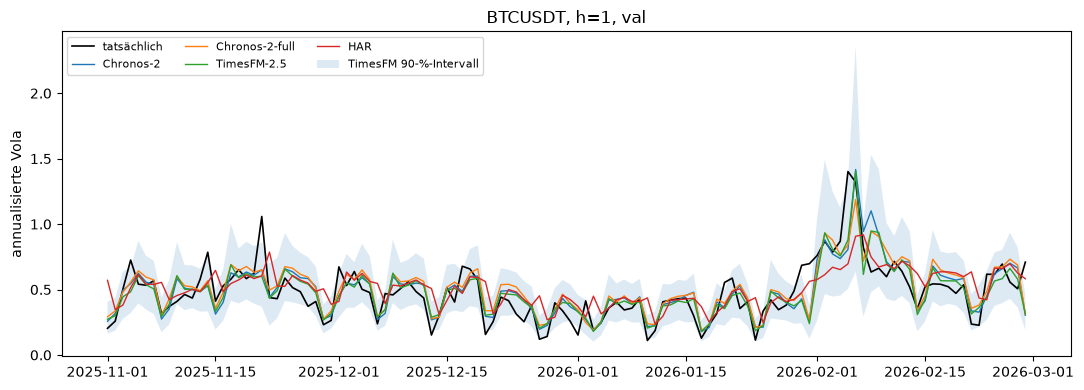

In [20]:
sel = fc[(fc["sid"] == "BTCUSDT") & (fc["h"] == 1) & (fc["split"] == "val")]
ann = lambda x: np.sqrt(365 * x)
fig, ax = plt.subplots(figsize=(11, 4))
truth = sel[sel["model"] == "HAR"].set_index("target_date")["y"]
ax.plot(ann(truth), color="black", lw=1.2, label="tatsächlich")
for m in [x for x in ["Chronos-2", "Chronos-2-full", "TimesFM-2.5", "HAR"] if x in HAVE]:
    d = sel[sel["model"] == m].set_index("target_date")
    ax.plot(ann(d["mean"]), lw=1, label=m)
d = sel[sel["model"] == "TimesFM-2.5"].set_index("target_date")
ax.fill_between(d.index, ann(d["q0.05"]), ann(d["q0.95"]), alpha=0.15, label="TimesFM 90-%-Intervall")
ax.set_ylabel("annualisierte Vola")
ax.set_title("BTCUSDT, h=1, val")
ax.legend(fontsize=8, ncol=3)
plt.tight_layout()
plt.show()

## 12. Wie weiter

- **Oracle-Beitrag von TimesFM deutlich > 0 und Oracle im 4er-Pool besser:** In `01_kombination.ipynb` TimesFM in `POOL` aufnehmen und die Gates neu trainieren.
- **Oracle-Beitrag nahe 0 und hohe Korrelation mit Chronos:** TimesFM bringt dem Gate wenig. Dann sind eher andersartige Experten oder mehr Coins der nächste Schritt.
- **`chronos-2-small` war im Einsatz:** In `01_kombination.ipynb` `Chronos-2-full` statt `Chronos-2` in `POOL` verwenden, damit der Vergleich mit TimesFM fair ist.